# 02 — EDA GameScope (top + mid-tail, base 2026-10-15)

Base: `data/processed/muestra_normalizada.csv` (950 top: 5 grupos × 2 páginas/fuente + extras Switch 2) + `muestra_midtail.csv` (200), observadas 2026-10-15. La cola aleatoria acumulativa (500 filas) NO entra aquí: su cobertura se mide aparte por oleada en `docs/06_kpis_snapshot.md`. Sesgo conocido: top-popular, así que esto describe el techo del mercado, no el long-tail.

Preguntas: P1 géneros dominantes · P2 distribución de puntuaciones · P3 relación crítica-usuarios · P4 cobertura temporal · P5 cobertura de plataformas · P6 concentración de estudios. Cada una termina en conclusión escrita + decisión para la app.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path("..")
rows = []
for fn in ("muestra_normalizada.csv", "muestra_midtail.csv"):
    rows += list(csv.DictReader((ROOT / "data" / "processed" / fn).open(encoding="utf-8")))

def num(v):
    try:
        return float(v) if v not in (None, "", "None") else None
    except ValueError:
        return None

print("Filas:", len(rows), "| RAWG:", sum(1 for r in rows if r["source"] == "rawg"),
      "| IGDB:", sum(1 for r in rows if r["source"] == "igdb"))

Filas: 1150 | RAWG: 500 | IGDB: 650


## P1 ¿Qué géneros dominan por fuente?

Conclusión: ambas coronan un cajón amplio (RAWG `Action` 404/500; IGDB `Adventure` 484/650) seguido de Shooter/RPG/Indie (RAWG 144–148; IGDB 195–218) y, en IGDB, `Puzzle` 136. La regla de competidor exige hoy ≥2 géneros en el **modo estricto** (implementado en `src/scoring.py --estricto` y en la web): con solo `Action` casi todo es candidato de todo.

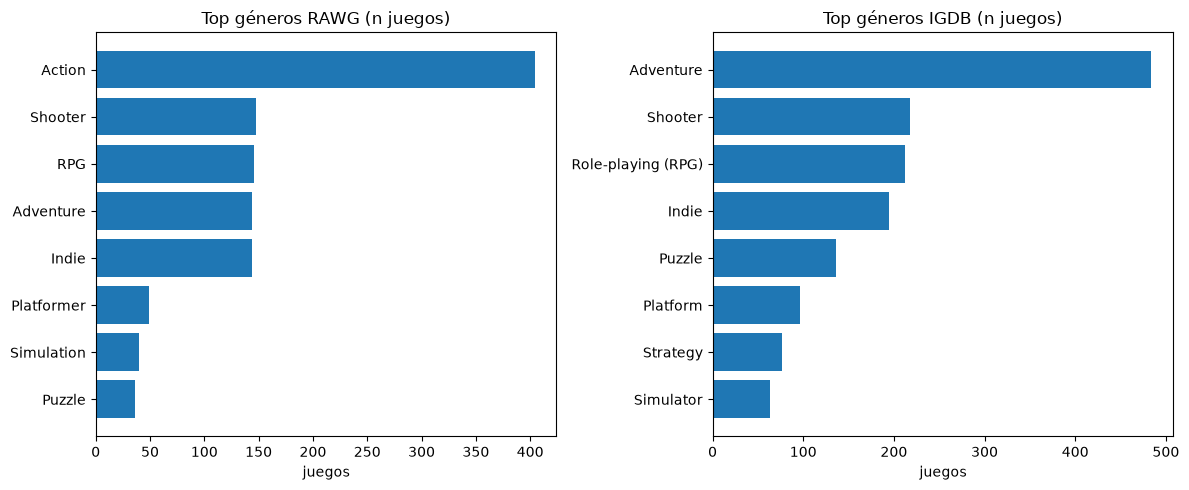

rawg [('Action', 404), ('Shooter', 148), ('RPG', 146), ('Adventure', 144), ('Indie', 144), ('Platformer', 49), ('Simulation', 40), ('Puzzle', 36)]
igdb [('Adventure', 484), ('Shooter', 218), ('Role-playing (RPG)', 212), ('Indie', 195), ('Puzzle', 136), ('Platform', 96), ('Strategy', 77), ('Simulator', 63)]


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=False)
for ax, src in zip(axes, ("rawg", "igdb")):
    c = Counter()
    for r in rows:
        if r["source"] == src:
            for x in (r["genre_names"] or "").split("|"):
                if x.strip():
                    c[x.strip()] += 1
    top = c.most_common(8)[::-1]
    ax.barh([k for k, _ in top], [v for _, v in top])
    ax.set_title(f"Top géneros {src.upper()} (n juegos)")
    ax.set_xlabel("juegos")
plt.tight_layout()
plt.show()
for src in ('rawg', 'igdb'):
    c = Counter()
    for r in rows:
        if r['source'] == src:
            for x in (r['genre_names'] or '').split('|'):
                if x.strip():
                    c[x.strip()] += 1
    print(src, c.most_common(8))

## P2 ¿Cómo se distribuyen las puntuaciones? (ojo: escalas distintas)

Medido: RAWG crítica 0–100 (med 84.0, n=477) vs usuarios 0–5 (med 4.12, n=500); IGDB agregada 0–100 (med 85.0, n=586) y usuarios 0–100 (med 82.9, n=600). Conclusión: medianas pegadas al techo por el sesgo top + escalas incompatibles entre fuentes → en la app, mostrar cada métrica con su escala y su n, nunca fusionar ni reescalar sin justificar.

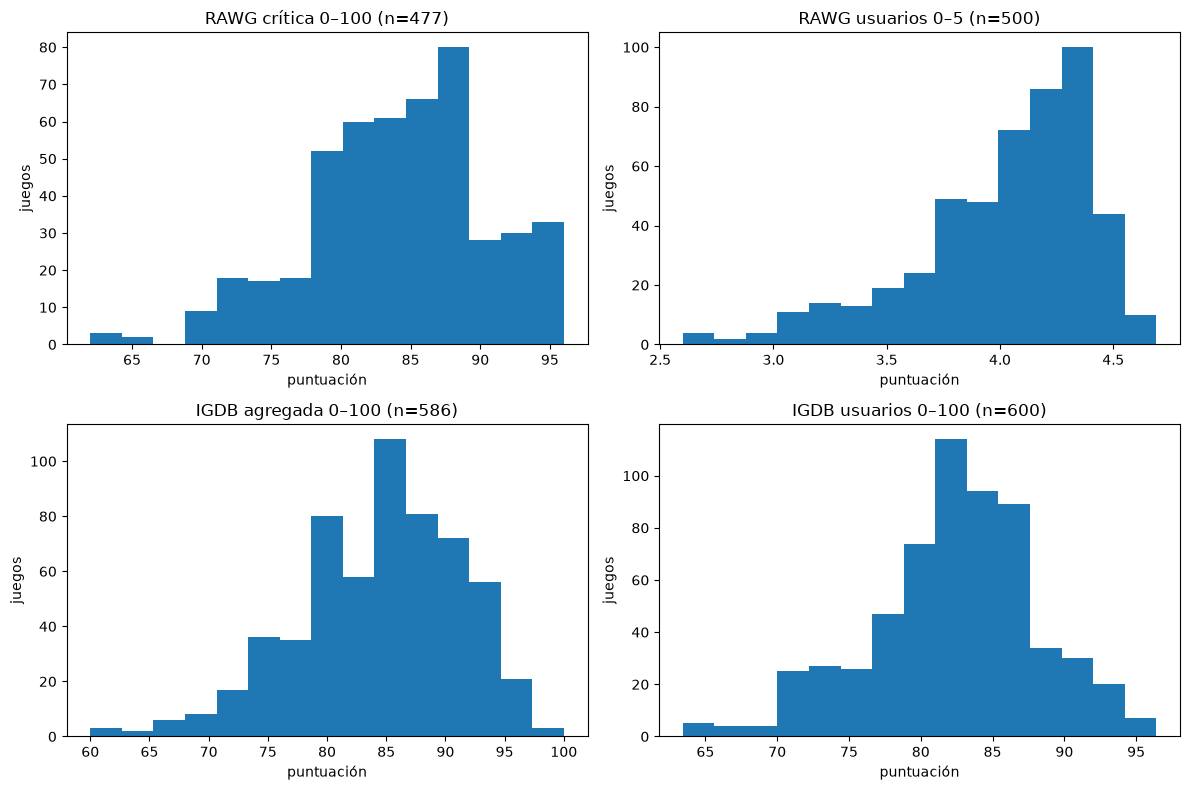

RAWG crítica 0–100: med=84.00 n=477
RAWG usuarios 0–5: med=4.12 n=500
IGDB agregada 0–100: med=85.00 n=586
IGDB usuarios 0–100: med=82.86 n=600


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
specs = [("rawg", "critic_score", "RAWG crítica 0–100"), ("rawg", "user_score", "RAWG usuarios 0–5"),
          ("igdb", "critic_score", "IGDB agregada 0–100"), ("igdb", "user_score", "IGDB usuarios 0–100")]
for ax, (src, col, title) in zip(axes.flat, specs):
    vs = [num(r[col]) for r in rows if r["source"] == src]
    vs = [x for x in vs if x is not None]
    ax.hist(vs, bins=15)
    ax.set_title(f"{title} (n={len(vs)})")
    ax.set_xlabel("puntuación"); ax.set_ylabel("juegos")
plt.tight_layout()
plt.show()
import statistics
for src, col, title in specs:
    vs = [num(r[col]) for r in rows if r['source'] == src]
    vs = [x for x in vs if x is not None]
    print(f'{title}: med={statistics.median(vs):.2f} n={len(vs)}')


## P3 ¿Crítica y usuarios se mueven juntos?

Medido: Pearson 0.64 en RAWG (n=477) y 0.68 en IGDB (n=586). Conclusión: correlación moderada-alta pero con dispersión real + n muy distintos (prensa IGDB mediana n=12, rango 1–52, frente a usuarios con miles de votos): sirven como dos señales complementarias lado a lado, y los conteos deben ponderar la confianza (un 90 con n=3 no vale lo mismo que con n=40).

rawg pearson: 0.644 n= 477
igdb pearson: 0.675 n= 586


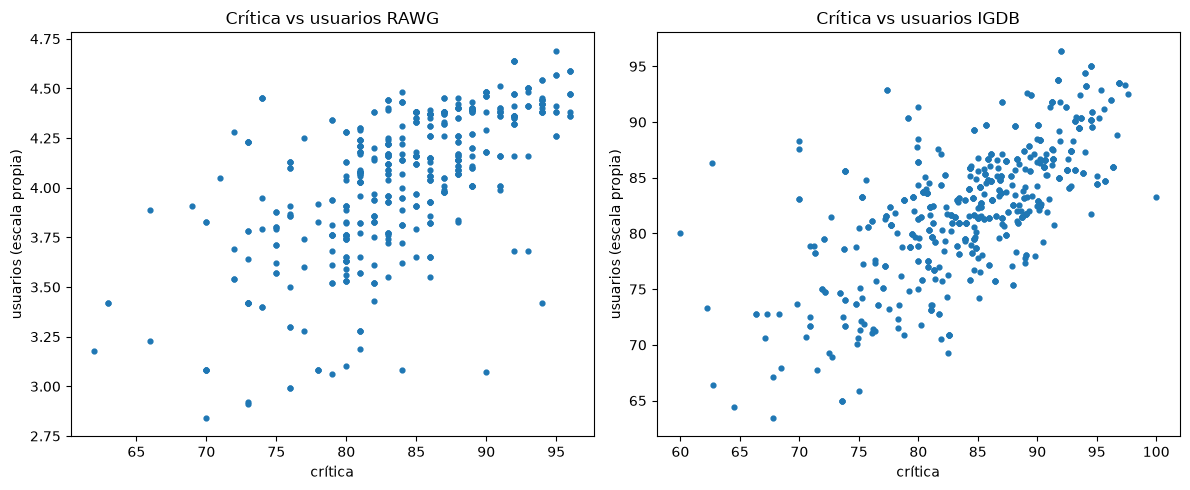

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, src in zip(axes, ("rawg", "igdb")):
    pairs = [(num(r["critic_score"]), num(r["user_score"])) for r in rows if r["source"] == src]
    pairs = [(a, b) for a, b in pairs if a is not None and b is not None]
    ax.scatter([a for a, _ in pairs], [b for _, b in pairs], s=12)
    ma = sum(a for a, _ in pairs) / len(pairs); mb = sum(b for _, b in pairs) / len(pairs)
    cov = sum((a - ma) * (b - mb) for a, b in pairs)
    va = sum((a - ma) ** 2 for a, _ in pairs); vb = sum((b - mb) ** 2 for _, b in pairs)
    print(src, "pearson:", round(cov / (va * vb) ** 0.5, 3), "n=", len(pairs))
    ax.set_title(f"Crítica vs usuarios {src.upper()}")
    ax.set_xlabel("crítica"); ax.set_ylabel("usuarios (escala propia)")
plt.tight_layout()
plt.show()

## P4 ¿Qué eras cubre la muestra?

Medido: mediana 2014 en RAWG (rango 1998–2022) y 2015 en IGDB (1978–2028; el extremo alto son anuncios aún sin salir). Conclusión: ventana útil para comparar contemporáneos; la regla era ±4 queda calibrada alrededor de 2010–2018, y los clásicos (pre-2000) necesitan tratamiento aparte (remasters) en vez de forzarlos como competidores directos.

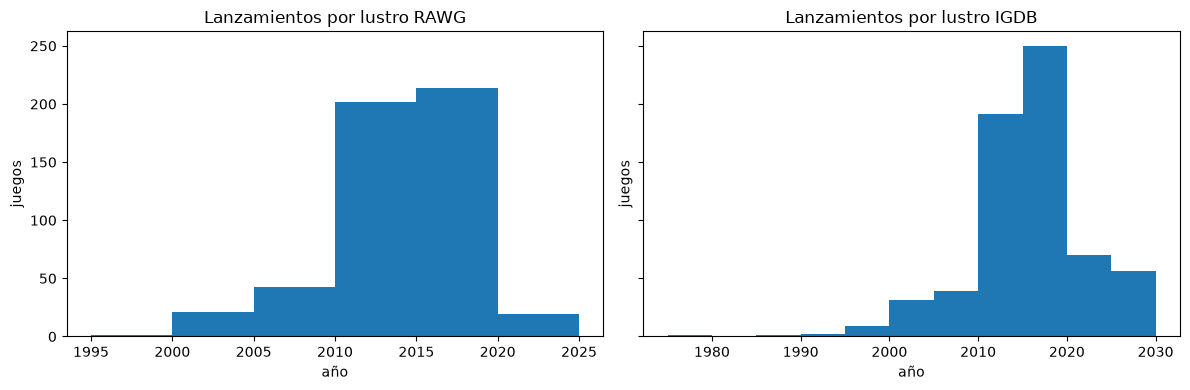

rawg mediana 2014 rango 1998 - 2022
igdb mediana 2015 rango 1978 - 2028


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, src in zip(axes, ("rawg", "igdb")):
    ys = [int(r["release_date"][:4]) for r in rows
          if r["source"] == src and (r["release_date"] or "")[:4].isdigit()]
    ax.hist(ys, bins=range(min(ys) // 5 * 5, max(ys) + 6, 5))
    ax.set_title(f"Lanzamientos por lustro {src.upper()}")
    ax.set_xlabel("año"); ax.set_ylabel("juegos")
plt.tight_layout()
plt.show()
for src in ('rawg', 'igdb'):
    ys = [int(r['release_date'][:4]) for r in rows
          if r['source'] == src and (r['release_date'] or '')[:4].isdigit()]
    print(src, 'mediana', int(statistics.median(ys)), 'rango', min(ys), '-', max(ys))

## P5 ¿Cobertura real de plataformas por grupo?

Medido: casi todo es multiplataforma (RAWG 498/500, IGDB 636/650) y PC domina el catálogo (497/500 y 618/650); Nintendo Switch 267/309. Móvil existe sobre todo en IGDB (iOS 224, Android 173) y parcialmente en RAWG (iOS 159, Android 135). Conclusión: el filtro por plataforma de la app es imprescindible: sin él, PC, Sony y Xbox muestran casi el mismo catálogo. Móvil es el único grupo con identidad propia parcial.

In [6]:
from collections import Counter
for src in ("rawg", "igdb"):
    c = Counter()
    for r in rows:
        if r["source"] == src:
            for x in (r["platform_names"] or "").split("|"):
                if x.strip():
                    c[x.strip()] += 1
    print(src, c.most_common(8))
    multi = sum(1 for r in rows if r["source"] == src and "|" in (r["platform_names"] or ""))
    n = sum(1 for r in rows if r["source"] == src)
    print(src, f"multiplataforma: {multi}/{n}")

rawg [('PC', 497), ('PlayStation 4', 394), ('Xbox One', 381), ('Nintendo Switch', 267), ('macOS', 265), ('Xbox 360', 194), ('Linux', 189), ('PlayStation 3', 162)]
rawg multiplataforma: 498/500
igdb [('PC (Microsoft Windows)', 618), ('PlayStation 4', 459), ('Xbox One', 424), ('Mac', 316), ('Nintendo Switch', 309), ('PlayStation 5', 238), ('iOS', 224), ('Xbox Series X', 209)]
igdb multiplataforma: 636/650


## P6 ¿Concentración de estudios?

Medido (IGDB): Ubisoft Montreal 30, Capcom Development Division 1 21, Telltale Games 20, FromSoftware 17, CD Projekt RED 14, Valve 14, Supergiant Games 13, Rockstar North 10. Conclusión: el top lo firman pocos estudios repetidos → el comparador no deja que "del mismo estudio" pese más que género+plataforma+era (el componente estudio vale 1.0 de 6.0 y solo aplica si ambas partes tienen el dato). RAWG-lista no permite este análisis: en esta muestra RAWG tiene 500/500 nulos en `developer_names` (dev/pub solo vía detalle, fuera del listado).

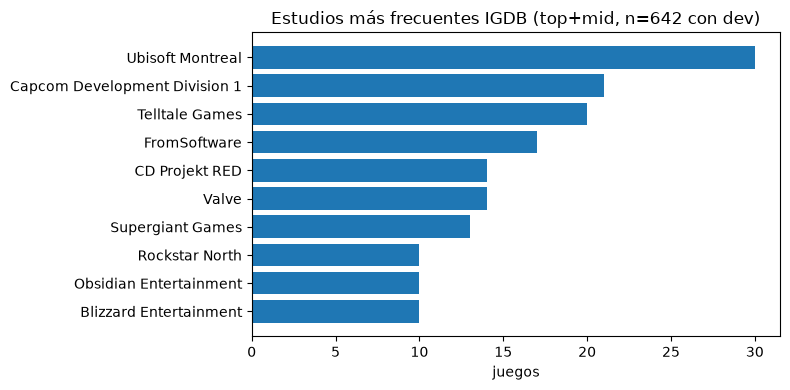

[('Ubisoft Montreal', 30), ('Capcom Development Division 1', 21), ('Telltale Games', 20), ('FromSoftware', 17), ('CD Projekt RED', 14), ('Valve', 14), ('Supergiant Games', 13), ('Rockstar North', 10), ('Obsidian Entertainment', 10), ('Blizzard Entertainment', 10)]


In [7]:
c = Counter()
for r in rows:
    if r["source"] == "igdb":
        for x in (r["developer_names"] or "").split("|"):
            if x.strip():
                c[x.strip()] += 1
top = c.most_common(10)[::-1]
plt.figure(figsize=(8, 4))
plt.barh([k for k, _ in top], [v for _, v in top])
n_dev = sum(1 for r in rows if r["source"] == "igdb" and (r["developer_names"] or "").strip())
plt.title(f"Estudios más frecuentes IGDB (top+mid, n={n_dev} con dev)")
plt.xlabel("juegos")
plt.tight_layout()
plt.show()
print(c.most_common(10))

## Decisiones para modelo y app (salen de este EDA)

1. Métricas siempre con escala + n visibles y sin fusionar (P2, P3).
2. Regla endurecida **implementada**: modo estricto con ≥2 géneros equivalentes + año obligatorio (`src/scoring.py --estricto` e interruptor en la web); la ponderación por rareza queda como evolución futura con fuente de catálogo que la sustente (P1).
3. Ponderar crítica por su n (mediana n=12, máx 52 en IGDB): desconfiar de agregados con n<5 (P3).
4. Filtro por plataforma obligatorio; móvil como grupo diferenciado (P5).
5. Ventana era ±4 válida 2010–2018; clásicos aparte (P4).
6. Componente estudio limitado (1.0/6.0, opcional si falta) para que el sello no domine (P6). Hecho: KPIs + snapshots versionado (ver `docs/06_kpis_snapshot.md`).